<a href="https://colab.research.google.com/github/mohammedibrahimshawon/Machine-Learning-Winter-2026/blob/main/exercise_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 2: Manifold Learning

**Note**: Please insert the names of all participating students:

1.
2.
3.
4.
5.

In [ ]:
import sys, os
if 'google.colab' in sys.modules:
  if os.getcwd() == '/content':
    !git clone 'https://github.com/inb-luebeck/cs5450.git'
    os.chdir('cs5450')

## Exercise 2.1: Multi-dimensional Scaling (MDS)

In this exercise, we will implement Multi-dimensional Scaling.

Implement the missing parts below. When done correctly, your code should do the following:
1. Generate a swiss roll dataset.
2. Compute the squared euclidean distances between samples.
3. Compute the gram matrix from squared distances and the centering matrix.
4. Sort the eigenvalues and corresponding eigenvectors of the gram matrix.
5. Calculate the MDS data representation with reduced dimensions.
6. Show the lower-dimensional representation of the data.

In case you are struggeling with the task, here are some helpful tips and hints:
1. Useful functions: [`make_swiss_roll`](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.make_swiss_roll.html), [`pdist`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.pdist.html), [`squareform`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.squareform.html), [`numpy.eye`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.eye.html), [`numpy.ones`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.ones.html), [`numpy.linalg.eig`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.linalg.eig.html), [`numpy.argsort`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.argsort.html), [`numpy.sqrt`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.sqrt.html), [`numpy.diag`](https://docs.scipy.org/doc/numpy/reference/generated/numpy.diag.html), [`Axes.scatter`](https://matplotlib.org/3.1.1/api/_as_gen/matplotlib.axes.Axes.scatter.html#matplotlib.axes.Axes.scatter), [`Axes3D.scatter`](https://matplotlib.org/3.1.1/api/_as_gen/mpl_toolkits.mplot3d.axes3d.Axes3D.html#mpl_toolkits.mplot3d.axes3d.Axes3D.scatter)

2. Additional references: [Color maps for matplotlib](https://matplotlib.org/examples/color/colormaps_reference.html)

Note: Don't use the MDS implementation provided by the sklearn package here.

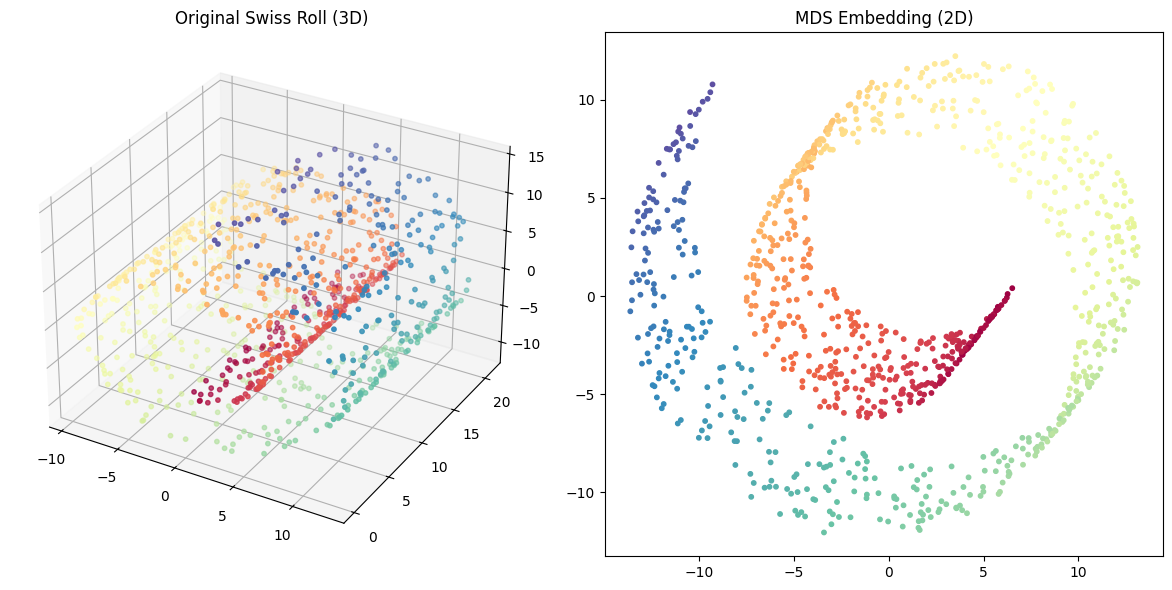

In [1]:

import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import make_swiss_roll

%matplotlib inline

# Define variables

# TODO number of random samples
n_samples = 1000

# Number of dimensions of the embedding
n_dims = 2

# TODO generate Swiss Roll data
data, color = make_swiss_roll(
    n_samples=n_samples,
    random_state=42
)

# TODO compute Euclidean distance vector
distances = pdist(data, metric='euclidean') #pdist()  caculate pair-এর distance.squareform() convert  1000 × 1000 matrix.

# TODO reshape into distance matrix
distances = squareform(distances)

# TODO square the distances
distances_squared = distances ** 2 # for MDS gram matrix formula

# TODO calculate the centering matrix H
I = np.eye(n_samples)
O = np.ones((n_samples, n_samples))
centering = I - (1 / n_samples) * O

# TODO compute the Gram matrix B
gram = -0.5 * centering @ distances_squared @ centering

# TODO compute eigenvalues and eigenvectors
eig_values, eig_vectors = np.linalg.eig(gram)

# Keep real values (matrix is symmetric)
eig_values = np.real(eig_values)
eig_vectors = np.real(eig_vectors)

# TODO sort eigenvalues in descending order
permutation = np.argsort(eig_values)[::-1]

# Rearrange eigenvectors
eig_vectors = eig_vectors[:, permutation]

# Rearrange eigenvalues
eig_values = eig_values[permutation]

# TODO calculate square roots
epsilon = 0.001
eig_values_root = np.sqrt(np.maximum(eig_values, 0) + epsilon)

# TODO reduce dimensions
data_mds = (
    eig_vectors[:, :n_dims]
    @ np.diag(eig_values_root[:n_dims])
)

# TODO visualize original data and embedding
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 6))

ax = fig.add_subplot(121, projection='3d')
ax.scatter(
    data[:, 0],
    data[:, 1],
    data[:, 2],
    c=color,
    cmap='Spectral',
    s=10
)
ax.set_title('Original Swiss Roll (3D)')

ax = fig.add_subplot(122)
ax.scatter(
    data_mds[:, 0],
    data_mds[:, 1],
    c=color,
    cmap='Spectral',
    s=10
)
ax.set_title('MDS Embedding (2D)')

plt.tight_layout()
plt.show()


## Exercise 2.2: Isomap

In this exercise, we will be implementing the Isomap algorithm.

You can use the MDS implementation from sklearn within your Isomap implementation.

Implement the missing parts below. When done correctly, your code should do the following:
1. Generate a swiss roll dataset.
2. Compute the euclidean distances between samples.
3. Sort the neighbors of each sample by distance.
4. Keep the closest k neighbors of each sample and set all other distances to infinity or NaN or zero to mark them as not-connected.
5. Calculate all shortest paths between pairs of samples (representing geodesic distances on the manifold).
6. Calculate the MDS data representation with reduced dimensions on the geodesic distances.
7. Show the lower-dimensional representation of the data.

In case you are struggeling with the task, here are some helpful tips and hints:
1. Useful functions:[`csgraph_from_dense`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.csgraph_from_dense.html), [`shortest_path`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.sparse.csgraph.shortest_path.html#scipy.sparse.csgraph.shortest_path), [`MDS`](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html)
2. Make sure to use MDS with `dissimilarity='precomputed'` so that it takes a distance matrix as input instead of a matrix of sample coordinates.

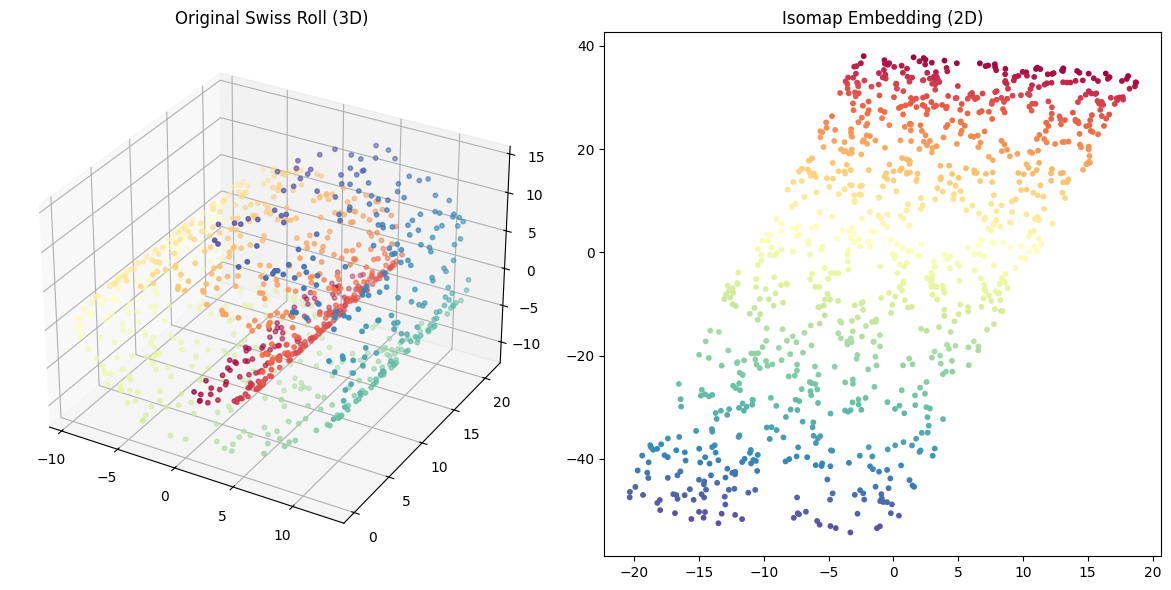

In [2]:

import numpy as np
from matplotlib import pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import csgraph_from_dense, shortest_path
from sklearn.manifold import MDS
from sklearn.datasets import make_swiss_roll

## Define variables

# TODO number of random samples
n_samples = 1000

# Number of dimensions of the embedding
n_dims = 2

# TODO number of nearest neighbors
n_neighbors = 10


## Compute and visualize the embedding using Isomap

# TODO generate data
data, color = make_swiss_roll(
    n_samples=n_samples,
    random_state=42
)

# TODO compute euclidean distance vector
distances = pdist(data, metric='euclidean')

# TODO reshape into distance matrix
distances = squareform(distances)

# TODO find the nearest neighbor-indices
permutation = np.argsort(distances, axis=1)


# TODO create the local distance matrix
distances_local = np.zeros((n_samples, n_samples))

for i in range(n_samples):

    # Select K nearest neighbors, excluding itself
    indices = permutation[i, 1:n_neighbors+1]

    # Store distances to nearest neighbors
    distances_local[i, indices] = distances[i, indices]


# Enforce distances_local to be symmetric
distances_local_transposed = distances_local.T

mask = (
    (distances_local == 0)
    & (distances_local_transposed != 0)
)

distances_local[mask] = distances_local_transposed[mask]


# TODO compute shortest paths
distances_geodesic = shortest_path(
    csgraph_from_dense(distances_local),
    directed=False
)

assert not np.any(np.isinf(distances_geodesic)), \
    'Error: manifold is fragmented into multiple disconnected regions.'


# TODO multidimensional scaling (MDS)
embedding = MDS(
    n_components=n_dims,
    dissimilarity='precomputed',
    random_state=42
)

data_isomap = embedding.fit_transform(distances_geodesic)


# TODO visualize original data and embedding
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(12, 6))

ax = fig.add_subplot(121, projection='3d')

ax.scatter(
    data[:, 0],
    data[:, 1],
    data[:, 2],
    c=color,
    cmap='Spectral',
    s=10
)

ax.set_title('Original Swiss Roll (3D)')


ax = fig.add_subplot(122)

ax.scatter(
    data_isomap[:, 0],
    data_isomap[:, 1],
    c=color,
    cmap='Spectral',
    s=10
)

ax.set_title('Isomap Embedding (2D)')

plt.tight_layout()
plt.show()


## Exercise 2.3: Comprehension Questions

Answer the following comprehension questions either with right or wrong and briefly explain your decision:

1. A manifold is a topological space that locally resembles Euclidean space near each point, e.g. a sphere.

Answer: A manifold locally resembles Euclidean space around each point, even if its global structure is curved. The surface of a sphere is an example of a two-dimensional manifold.

2. The features found by classical MDS are equivalent to the ones computed by ICA.

WRONG Answer: Classical MDS with Euclidean distances produces an embedding equivalent to PCA scores up to an orthogonal transformation, not ICA. ICA aims to find statistically independent components.

3. Isomap replaces the Euclidean distance measure used by MDS with geodesic distances.

Answer: Isomap estimates geodesic distances using shortest paths in a nearest-neighbor graph and applies MDS to these distances.

4. Local Linear Embedding (LLE) seeks a lower-dimensional projection of the data trying to preserve the distances within a local neighborhood.

WRONG
Answer: LLE preserves local linear reconstruction weights rather than pairwise distances between neighboring data points.

5. Unlike MDS, LLE uses global properties of the manifold to find an embedding.

WRONG
Answer: LLE uses local neighborhood properties to construct a global embedding, whereas MDS considers pairwise distances across the entire dataset.

6. $n+1$ non-collinear points of two distinct classes are always linearly separable in $\mathbb{R}^n$.

WRONG — as written
Answer: Non-collinearity alone is insufficient in higher dimensions. The \(n+1\) points must be affinely independent to guarantee linear separability for every possible binary labeling.

7. The reason that the kernel trick can be applied is that the observations only show up in pairs of inner products.

RIGHT
Answer: The kernel trick can be applied when an algorithm depends on observations only through pairwise inner products, allowing these inner products to be replaced by kernel evaluations.

8. To apply the kernel trick, the function $\boldsymbol{\Phi} \left( \vec{x} \right)$ must be explicitly known.

WRONG
Answer: The feature mapping \(\Phi(x)\) does not need to be explicitly known. The kernel function directly computes the inner product in the corresponding feature space.

9. The function $\boldsymbol{\Phi} \left( \vec{x} \right) = \boldsymbol{\Phi} \left( \left[x_1, x_2 \right] \right) = \left[ x_1^2, \sqrt{2} x_1 x_2, x_2^2\right]$ is a function of the kernel $K \left( \vec{x}, \vec{y} \right) = \langle \vec{x}, \vec{y}\rangle^2$. This function is unique.

WRONG
Answer: The given feature mapping correctly represents the polynomial kernel, but it is not unique. Other feature mappings, such as orthogonal transformations of the given mapping, can produce the same kernel.